<a href="https://colab.research.google.com/github/yurajsinghyadav33-dotcom/image-pixel-manipulation/blob/main/Image_Pixel_Manipulator_(Synthetic_Images).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

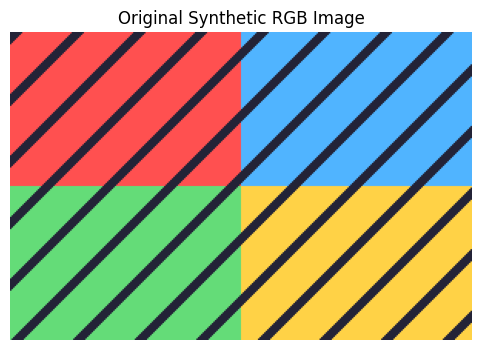

Image shape: (200, 300, 3)
Data type: uint8


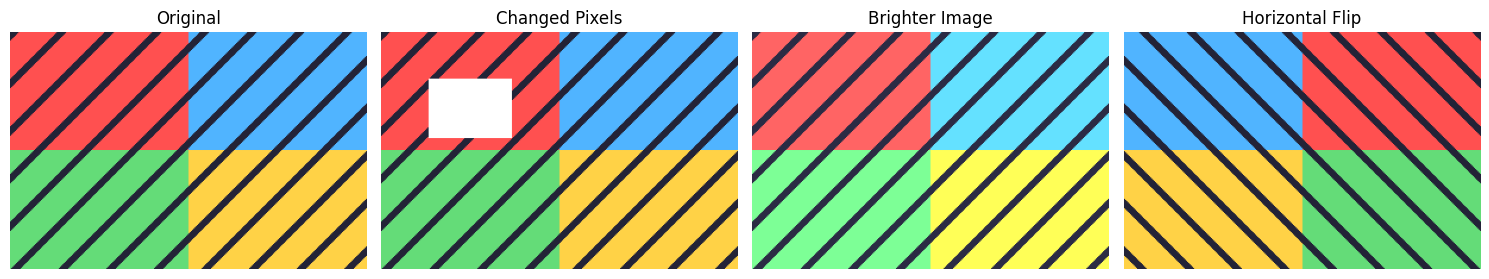

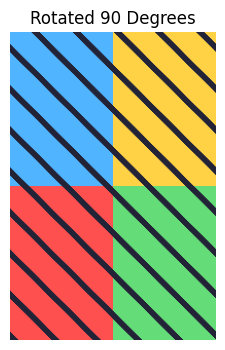

Vectorized and loop results should be visually similar.
851 µs ± 167 µs per loop (mean ± std. dev. of 7 runs, 1000 loops each)
670 ms ± 176 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# Create a synthetic RGB image (height x width x RGB channels)
height, width = 200, 300
image = np.zeros((height, width, 3), dtype=np.uint8)

# Create colorful synthetic regions using array slicing
image[:100, :150] = [255, 80, 80]       # Red region
image[:100, 150:] = [80, 180, 255]      # Blue region
image[100:, :150] = [100, 220, 120]     # Green region
image[100:, 150:] = [255, 210, 70]      # Yellow region

# Add a deterministic pixel pattern
y, x = np.indices((height, width))
pattern = ((x + y) % 40 < 8)
image[pattern] = [35, 35, 55]

plt.figure(figsize=(7, 4))
plt.imshow(image)
plt.title("Original Synthetic RGB Image")
plt.axis("off")
plt.show()

print("Image shape:", image.shape)
print("Data type:", image.dtype)
# 1. Manipulate pixel colors using slicing
color_changed = image.copy()
color_changed[40:90, 40:110] = [255, 255, 255]  # White rectangle

# 2. Adjust brightness using broadcasting
brightened = np.clip(image.astype(float) * 1.25, 0, 255).astype(np.uint8)

# 3. Flip and rotate
flipped = image[:, ::-1, :]
rotated = np.rot90(image)

fig, axes = plt.subplots(1, 4, figsize=(15, 4))
items = [
    (image, "Original"),
    (color_changed, "Changed Pixels"),
    (brightened, "Brighter Image"),
    (flipped, "Horizontal Flip")
]
for ax, (img, title) in zip(axes, items):
    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

plt.figure(figsize=(5, 4))
plt.imshow(rotated)
plt.title("Rotated 90 Degrees")
plt.axis("off")
plt.show()
# 4. Compare vectorized operation with pixel loops
def vectorized_brightness(img):
    return np.clip(img.astype(float) * 1.1, 0, 255).astype(np.uint8)

def loop_brightness(img):
    h, w, channels = img.shape
    result = np.empty_like(img)
    for i in range(h):
        for j in range(w):
            for c in range(channels):
                result[i, j, c] = min(255, int(img[i, j, c] * 1.1))
    return result

# %timeit works in Google Colab / IPython
print("Vectorized and loop results should be visually similar.")
%timeit vectorized_brightness(image)
%timeit loop_brightness(image)
